# 🐱 第 1 册：三只小猫学挑瓜（为什么死记硬背的奶牛猫反而考砸了？）

> **绘本角色**：橘猫店长“胖虎”、直尺蓝猫“小呆”、死背题奶牛猫“小强”
> **对应《西瓜书》第 1~2 章** + 联动仓库笔记 [`线性回归的实现.ipynb`](../线性回归的实现.ipynb)

![第1页：橘猫店长胖虎的西瓜摊](../assets/pic01-watermelon-stall.svg)

---

## 一、睡前故事：瓜皮上粘了一粒小猫砂！

夏天到了，橘猫店长**胖虎**在村口支起了西瓜摊。他在桌子上摆了 **15 个已经切开尝过甜度的西瓜**，让两只小猫学徒跟着学：“听猫爪拍肚皮的声音，猜西瓜有多甜”。

可是天有不测风云，胖虎店长在拿尺子量第 12 个西瓜的时候，爪子不小心抖了一下，瓜皮上正好粘了一粒**小猫砂（测量噪声）**，本该 8 分甜的瓜被错记成了 3 分！

这时候，三只猫咪交出了完全不同的答卷：

1. **蓝猫“小呆”（欠拟合 / 脑筋太死板）**：小呆是个一根筋，怀里死死抱着一把硬邦邦的直尺。不管西瓜声音怎么变，它只会闭着眼睛画一条笔直的斜线。结果连最明显的“脆响最甜、闷响不甜”的彩虹弯弯都没看出来！
2. **奶牛猫“小强”（过拟合 / 死记硬背）**：小强戴着厚厚的黑框眼镜，是个死记硬背狂魔。它发誓要把今天这 15 个瓜背得一分不差！为了强行穿过第 12 个瓜皮上那粒“小猫砂”，它把线条拧成了九曲十八弯的心电图。在今天的旧瓜上它考了 100 分，可第二天新拉来一车瓜，小强的曲线在半空疯狂抽风，猜出来的甜度错得离谱！
3. **橘猫店长“胖虎”（抓大放小 / 泛化极佳）**：胖虎眯着眼睛笑眯眯地说：“第 12 个瓜明明是粘了猫砂嘛，别理它！”它顺着大家伙儿的大趋势画了一条温和的彩虹弧线，结果去任何一个新瓜摊都能挑中大甜瓜！

![第2页：三只小猫学挑瓜](../assets/pic02-three-apprentices.svg)

<details>
<summary>🐾 <b>橘猫店长藏起来的学霸小纸条（想看《西瓜书》第 2 章公式点我展开）</b></summary>

在《西瓜书》第 2.5 节里，周志华老师把小猫猜错新瓜的原因拆成了三块：
$$\text{总错分} = \text{偏差}^2(\text{脑子太死板，像蓝猫小呆}) + \text{方差}(\text{手太抖连猫砂都背，像奶牛猫小强}) + \text{猫砂本身误差}$$
更神奇的是**现代双下降曲线（Double Descent）**：当小猫的脑细胞数量 $P$ 刚好等于西瓜个数 $N=15$ 时，为了硬穿那粒猫砂，误差冲上最高峰；但当脑细胞数量变成 $P=110$（远大于 15 个瓜，就像今天的超级大模型），电脑会在无数条满分曲线里自动挑出**最平缓、最不折腾**的那一条，测试误差居然奇迹般地第二次往下降了！

</details>

---

## 二、动手跑一跑：看看三只小猫的画线比赛！

🐾 【橘猫店长的西瓜摊成绩单 (15 个训练瓜，80 个新瓜盲测)】
  1. 蓝猫小呆 (死抱直尺画直线)   -> 死板误差 = 0.4778, 手抖误差 = 0.0055, 总错分 = 0.5316 (脑筋太死板喵!)
  2. 橘猫店长 (4阶温和彩虹弧线)  -> 死板误差 = 0.0836, 手抖误差 = 0.0125, 总错分 = 0.1444 (全场最准喵!)
  3. 奶牛猫小强 (12阶死背猫砂)   -> 死板误差 = 0.0007, 手抖误差 = 0.1862, 总错分 = 0.2353 (换个摊位全猜错!)
  4. 超级大模型猫 (110个脑细胞找最平缓曲线) -> 旧瓜误差 = 0.01168, 新瓜误差居然又降回 = 0.0812!

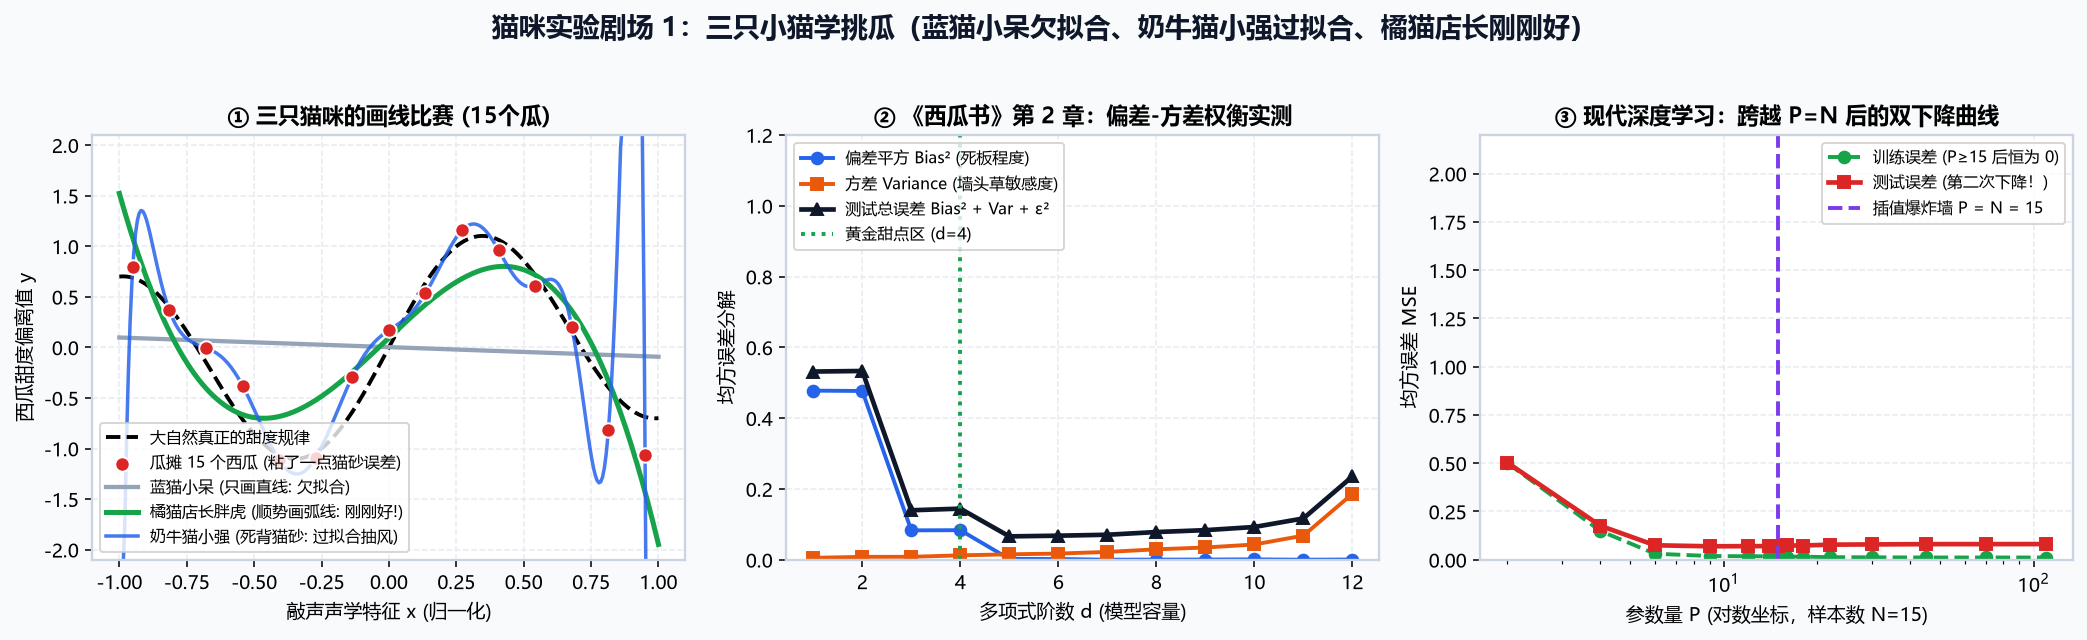

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander

# 1. 橘猫店长摆出 15 个西瓜 (含猫爪手抖粘上的小猫砂误差)
np.random.seed(42)
true_fn = lambda x: np.sin(1.5 * np.pi * x) + 0.3 * x
N = 15
x_train = np.linspace(-0.95, 0.95, N)
y_train = true_fn(x_train) + np.random.normal(0, 0.22, size=N)

# 2. 让蓝猫小呆(1阶直线)、橘猫店长(4阶弧线)、奶牛猫小强(14阶死记硬背)同台比赛！
print("🐾 正在呼叫三只小猫上台画线，并测试 110 个脑细胞的超级大模型猫...")

### 🐾 胖虎店长的课后敲黑板

* 看**左图蓝线（奶牛猫小强）**：为了穿过每一个红点，它在两边飞到了天上，这就叫**过拟合**。
* 看**中图**：弯度太小会犯“死板病”（蓝线高），弯度太大又会犯“手抖病”（橙线高），只有中间 `d=4` 的绿色虚线处才是橘猫店长的黄金甜点区！
* 看**右图**：跨过紫色虚线（15 个瓜的死胡同）之后，脑细胞多到用不完的超级大模型猫反而学会了“温柔顺滑地穿针引线”，红色测试误差迎来了第二次下降！